# Exploración de datasets y casos de uso para machine learning no supervisado

**Autor:** Witman Zavala M.
 **Objetivo**:
Identificar una fuente de datos confiable y proponer un problema relevante que pueda ser resuelto utilizando técnicas de Machine Learning no supervisado, justificando su importancia y viabilidad.

# Desarrollo

# Parte 1: Exploración de datasets y problemas

# a).- Revisa al menos 10 datasets.

## 1.-Dataset -Estadísticas macroeconómicas chile 2003-2025 venta y producción banco central chile.xlsx

In [ ]:
import pandas as pd
from tabulate import tabulate

url = "https://raw.githubusercontent.com/witman92/unsupervised-ml-use-case-discovery/54524705243fdefe8d5baf8b39d28c26e55b432d/1.-Dataset%20-Estad%C3%ADsticas%20macroecon%C3%B3micas%20chile%202003-2025%20venta%20y%20producci%C3%B3n%20banco%20central%20chile.xlsx"
data = pd.read_excel(url, sheet_name=None)  # Leer todas las hojas

sheet_names = list(data)  # Nombres de hojas
print("Hojas encontradas:\n" + '\n'.join(f"{i+1}. {name}" for i, name in enumerate(sheet_names)))

df = data[sheet_names[0]]  # Seleccionar primera hoja
print(f"\nPrimeros datos de '{sheet_names[0]}':")
print(tabulate(df.head(10), headers='keys', tablefmt='pretty', showindex=False))  # Mostrar primeras 10 filas
print(f"\nDimensiones: {df.shape}")  # Mostrar tamaño


Hojas encontradas:
1. Cuadro

Primeros datos de 'Cuadro':
+---------------------+--------------------------------------------------------------------+-------------------------------------------------------------------------+--------------------------------------------------------------------------------+-----------------------------------------------+-------------------------------------------------+------------------------------------------------------------------------+---------------------------------------------------------------------+-------------------------------------------+
|       Periodo       | 1.1. Índice de producción industrial, minería, INE (base 2018=100) | 1.2. Índice de producción industrial, manufacturas, INE (base 2018=100) | 1.3. Índice de Producción Industrial, Energía, Gas y Agua, INE (base 2018=100) | 2. Generación de energía eléctrica CDEC (GWh) | 3. Índice de ventas reales, INE (base 2018=100) | 3.1. Índice de ventas reales, bienes no duraderos, INE (base 20

## 2.-Datset-Personas en RSH beneficiadas por el SUF según edad - 2025.csv

In [ ]:
import pandas as pd
from tabulate import tabulate

url = "https://raw.githubusercontent.com/witman92/unsupervised-ml-use-case-discovery/54524705243fdefe8d5baf8b39d28c26e55b432d/2.-Datset-Personas%20en%20RSH%20beneficiadas%20por%20el%20SUF%20seg%C3%BAn%20edad%20-%202025.csv"
data = pd.read_csv(url, encoding='latin1', delimiter=';')  # Leer CSV con codificación y separador

df = data
print(f"\nPrimeros datos:")
print(tabulate(df.head(10), headers='keys', tablefmt='pretty', showindex=False))  # Mostrar primeras 10 filas
print(f"\nDimensiones: {df.shape}")  # Mostrar tamaño



Primeros datos:
+---------+--------+--------+----------------+----------------------------------------------------------+------------------------------------------------------------+------------------------------------------------------------+--------------------------------------------------------+----------------------------------------------------------+------------------------------------------------------------+------------------------------------------------------------+--------------------------------------------------------+----------------------------------------------------+------------------------------------------------------+------------------------------------------------------+--------------------------------------------------+-----------------------------------------------------------+-------------------------------------------------------------+-------------------------------------------------------------+---------------------------------------------------------+-----

## 3.-Dataset- audio de 4 horas de español americano, 5159 enunciados y 10 hablantes

In [ ]:
!pip install tabulate
!pip install ipython

In [ ]:
import os, requests, zipfile, pandas as pd
from IPython.display import Audio, display

# === Parámetros ===
URL = 'https://media.githubusercontent.com/media/witman92/unsupervised-ml-use-case-discovery/refs/heads/main/5.-Dataset%20audio%20con%204%20horas%20de%20espa%C3%B1ol%20americano%205159%20enunciados%20y%2010%20hablantes.?download=true'
ZIP, DEST = 'dataset_audio.zip', './descargas/audio_extraido'
WAV_DIR, EXT, MAX = os.path.join(DEST, 'WAV'), '.wav', 10

def descargar(url, path):
    if os.path.exists(path): return print(f"📁 '{path}' ya existe. Descarga omitida.") or True
    print("⬇️ Descargando...")
    try:
        r = requests.get(url, stream=True); r.raise_for_status()
        with open(path, 'wb') as f: [f.write(c) for c in r.iter_content(8192)]
        print(f"✅ Descargado: {path}"); return True
    except Exception as e: print(f"❌ Error al descargar: {e}"); return False

def extraer(zip_path, destino):
    if os.path.exists(destino): return print("📂 Carpeta ya existe. Extracción omitida.") or True
    print("📦 Extrayendo...")
    try:
        with zipfile.ZipFile(zip_path, 'r') as z: z.extractall(destino)
        print(f"✅ Extraído en: {destino}"); return True
    except Exception as e: print(f"❌ Error al extraer: {e}"); return False

def crear_df_audios(ruta, ext=EXT, max_audios=MAX):
    data = {
        sub: sorted([f for f in os.listdir(os.path.join(ruta, sub)) if f.endswith(ext)])[:max_audios]
        for sub in sorted(os.listdir(ruta)) if os.path.isdir(os.path.join(ruta, sub))
    }
    if not data: return pd.DataFrame()
    max_len = max(map(len, data.values()))
    return pd.DataFrame({k: v + [None]*(max_len - len(v)) for k, v in data.items()})

def reproducir(df, base, limite=5):
    if df.empty: return print("⚠️ No hay audios para reproducir.")
    print(f"\n🔊 Reproduciendo los primeros {limite} audios:\n")
    count = 0
    for sub in df.columns:
        for f in df[sub].dropna():
            if count >= limite: return
            ruta = os.path.join(base, sub, f)
            if os.path.isfile(ruta):
                print(f"📁 {sub} | 🎙️ {f}")
                display(Audio(filename=ruta))
                count += 1

def main():
    if descargar(URL, ZIP) and extraer(ZIP, DEST):
        print(f"📂 Archivos cargados desde: {WAV_DIR}")
        df = crear_df_audios(WAV_DIR)
        if not df.empty:
            print("\n🎧 Tabla de audios por subcarpeta:\n"); display(df)
            reproducir(df, WAV_DIR)
        else: print("⚠️ No se encontraron archivos .wav.")

if __name__ == "__main__":
    main()


📁 'dataset_audio.zip' ya existe. Descarga omitida.
📂 Carpeta ya existe. Extracción omitida.
📂 Archivos cargados desde: ./descargas/audio_extraido/WAV

🎧 Tabla de audios por subcarpeta:



,G0020,G0024,G0027,G0032,G0034,G0045,G0047,G0049,G0051,G0052
0,G0020_S0004.wav,G0024_S0001.wav,G0027_S0001.wav,G0032_S0001.wav,G0034_S0001.wav,G0045_S0001.wav,G0047_S0003.wav,G0049_S0002.wav,G0051_S0001.wav,G0052_S0002.wav
1,G0020_S0005.wav,G0024_S0002.wav,G0027_S0002.wav,G0032_S0002.wav,G0034_S0003.wav,G0045_S0002.wav,G0047_S0005.wav,G0049_S0007.wav,G0051_S0002.wav,G0052_S0003.wav
2,G0020_S0006.wav,G0024_S0003.wav,G0027_S0005.wav,G0032_S0003.wav,G0034_S0004.wav,G0045_S0003.wav,G0047_S0006.wav,G0049_S0008.wav,G0051_S0006.wav,G0052_S0004.wav
3,G0020_S0008.wav,G0024_S0004.wav,G0027_S0007.wav,G0032_S0005.wav,G0034_S0008.wav,G0045_S0005.wav,G0047_S0007.wav,G0049_S0009.wav,G0051_S0007.wav,G0052_S0006.wav
4,G0020_S0010.wav,G0024_S0007.wav,G0027_S0008.wav,G0032_S0007.wav,G0034_S0009.wav,G0045_S0007.wav,G0047_S0008.wav,G0049_S0012.wav,G0051_S0008.wav,G0052_S0007.wav
5,G0020_S0011.wav,G0024_S0008.wav,G0027_S0009.wav,G0032_S0008.wav,G0034_S0012.wav,G0045_S0009.wav,G0047_S0010.wav,G0049_S0014.wav,G0051_S0010.wav,G0052_S0009.wav
6,G0020_S0012.wav,G0024_S0009.wav,G0027_S0010.wav,G0032_S0009.wav,G0034_S0013.wav,G0045_S0011.wav,G0047_S0014.wav,G0049_S0015.wav,G0051_S0012.wav,G0052_S0010.wav
7,G0020_S0013.wav,G0024_S0010.wav,G0027_S0011.wav,G0032_S0010.wav,G0034_S0017.wav,G0045_S0013.wav,G0047_S0015.wav,G0049_S0016.wav,G0051_S0013.wav,G0052_S0012.wav
8,G0020_S0014.wav,G0024_S0011.wav,G0027_S0012.wav,G0032_S0011.wav,G0034_S0018.wav,G0045_S0014.wav,G0047_S0016.wav,G0049_S0017.wav,G0051_S0014.wav,G0052_S0013.wav
9,G0020_S0015.wav,G0024_S0013.wav,G0027_S0015.wav,G0032_S0012.wav,G0034_S0021.wav,G0045_S0015.wav,G0047_S0017.wav,G0049_S0019.wav,G0051_S0017.wav,G0052_S0014.wav



🔊 Reproduciendo los primeros 5 audios:

📁 G0020 | 🎙️ G0020_S0004.wav


📁 G0020 | 🎙️ G0020_S0005.wav


📁 G0020 | 🎙️ G0020_S0006.wav


📁 G0020 | 🎙️ G0020_S0008.wav


📁 G0020 | 🎙️ G0020_S0010.wav


## 4.-Dataset-Índices de movilidad interna y externa entre comunas, viajes internosexternal por población, con fecha chile .csv

In [ ]:
import pandas as pd
from tabulate import tabulate

# URL RAW del dataset CSV (contenido bruto de GitHub)
url = "https://raw.githubusercontent.com/witman92/unsupervised-ml-use-case-discovery/7bb3ce7800cf6c0f2e56598fade155fef44a7d05/7.-Dataset-%C3%8Dndices%20de%20movilidad%20interna%20y%20externa%20entre%20comunas%2C%20viajes%20internosexternal%20por%20poblaci%C3%B3n%2C%20con%20fecha..csv"

try:
    # Cargar el dataset desde la URL RAW
    df = pd.read_csv(url, encoding='utf-8', sep=',')

    # Mostrar las primeras 10 filas en formato tabular
    print("\nPrimeros datos:")
    print(tabulate(df.head(10), headers='keys', tablefmt='pretty', showindex=False))

    # Mostrar las dimensiones del DataFrame
    print(f"\nDimensiones: {df.shape[0]} filas × {df.shape[1]} columnas")

except Exception as e:
    # Mostrar mensaje de error si falla la carga
    print(f"\nError al cargar el archivo CSV: {e}")



Primeros datos:
+----------+-----+----------+-------+---------+--------------------+--------------------+--------------------+------------+
|  region  | rid |  comuna  |  cid  |  area   |     IM_interno     |     IM_externo     |         IM         |    date    |
+----------+-----+----------+-------+---------+--------------------+--------------------+--------------------+------------+
| Los Ríos | 14  | Valdivia | 14101 | 1018.32 | 6.219609775896559  |  0.91566404777781  | 7.1352738236743685 | 2020-02-26 |
| Los Ríos | 14  | Valdivia | 14101 | 1018.32 | 6.4209259849824605 | 0.9305076392311484 | 7.351433624213609  | 2020-02-27 |
| Los Ríos | 14  | Valdivia | 14101 | 1018.32 | 6.759951294465544  | 1.0848577972342213 | 7.844809091699765  | 2020-02-28 |
| Los Ríos | 14  | Valdivia | 14101 | 1018.32 | 6.887658365465457  | 1.1718319659061258 | 8.059490331371581  | 2020-02-29 |
| Los Ríos | 14  | Valdivia | 14101 | 1018.32 | 5.585220189603689  | 1.0527353376047317 | 6.637955527208419  | 2020

## 5.-Dataset Chile Precipitación diaria y mensual para varias estaciones, largo historial (desde 1930 para algunas)-2020.xlsx

In [ ]:
import pandas as pd
from tabulate import tabulate

# URL RAW del archivo Excel (.xlsx)
url = "https://raw.githubusercontent.com/witman92/unsupervised-ml-use-case-discovery/7bb3ce7800cf6c0f2e56598fade155fef44a7d05/8.-Dataset%20Chile%20Precipitaci%C3%B3n%20diaria%20y%20mensual%20para%20varias%20estaciones%2C%20largo%20historial%20(desde%201930%20para%20algunas)-2020.xlsx"

try:
    # Leer archivo Excel desde la URL
    df = pd.read_excel(url)

    # Mostrar las primeras 10 filas en formato tabular
    print("\nPrimeros datos:")
    print(tabulate(df.head(10), headers='keys', tablefmt='pretty', showindex=False))

    # Mostrar las dimensiones del DataFrame
    print(f"\nDimensiones: {df.shape[0]} filas × {df.shape[1]} columnas")

except Exception as e:
    # Mostrar mensaje de error si falla la carga
    print(f"\nError al cargar el archivo Excel: {e}")



Primeros datos:
+-----------------+-------------+---------+-----------------------------+--------+----------+----------+---------------+--------------------------+-------------------+---------------------------------------+----------------------+-------------------+------------------------+-------------------+
| codigo_estacion | institucion | fuente  |           nombre            | altura | latitud  | longitud | codigo_cuenca |      nombre_cuenca       | codigo_sub_cuenca |           nombre_sub_cuenca           | inicio_observaciones | fin_observaciones | cantidad_observaciones | inicio_automatica |
+-----------------+-------------+---------+-----------------------------+--------+----------+----------+---------------+--------------------------+-------------------+---------------------------------------+----------------------+-------------------+------------------------+-------------------+
|     1000005     |     DGA     | dga_web |           Visviri           |  4080  | -17.595  | -

## 6.-Dataset Datos sintéticos de análisis de comercio electrónico.csv

In [ ]:
import pandas as pd
from tabulate import tabulate

# URL RAW del dataset CSV (contenido bruto de GitHub)
url = "https://raw.githubusercontent.com/witman92/unsupervised-ml-use-case-discovery/7bb3ce7800cf6c0f2e56598fade155fef44a7d05/9.-Dataset%20Datos%20sint%C3%A9ticos%20de%20an%C3%A1lisis%20de%20comercio%20electr%C3%B3nico.csv"

try:
    # Cargar el dataset desde la URL RAW
    df = pd.read_csv(url, encoding='utf-8', sep=',')

    # Mostrar las primeras 10 filas en formato tabular
    print("\nPrimeros datos:")
    print(tabulate(df.head(10), headers='keys', tablefmt='pretty', showindex=False))

    # Mostrar las dimensiones del DataFrame
    print(f"\nDimensiones: {df.shape[0]} filas × {df.shape[1]} columnas")

except Exception as e:
    # Mostrar mensaje de error si falla la carga
    print(f"\nError al cargar el archivo CSV: {e}")



Primeros datos:
+--------------------------------------+----------------+-------------+------------------+------------+------------------+---------+--------+-------------+-----------------+-----------------+---------------+--------+--------+----------+
|            Transaction_ID            |  Customer_ID   | Product_ID  | Transaction_Date | Units_Sold | Discount_Applied | Revenue | Clicks | Impressions | Conversion_Rate |    Category     |    Region     | Ad_CTR | Ad_CPC | Ad_Spend |
+--------------------------------------+----------------+-------------+------------------+------------+------------------+---------+--------+-------------+-----------------+-----------------+---------------+--------+--------+----------+
| 8b460852-7c64-46fa-998b-b0976879d082 |  Customer_65   | Product_224 |    2024-10-06    |    134     |       0.14       | 305.54  |   11   |     65      |      0.17       |   Electronics   |    Europe     | 0.018  |  0.55  |   9.9    |
| 418612e7-8744-4ba3-bb0c-105b47e2a

## 7.-Dataset  cobertura mediática digital chilena (conflictos socioambientales) Twitter, Facebook, Instagram.xlsx

In [ ]:
import pandas as pd
from tabulate import tabulate

# URL RAW del archivo Excel (.xlsx)
url = "https://raw.githubusercontent.com/witman92/unsupervised-ml-use-case-discovery/7bb3ce7800cf6c0f2e56598fade155fef44a7d05/10.-Dataset%20%20cobertura%20medi%C3%A1tica%20digital%20chilena%20(conflictos%20socioambientales)%20Twitter%2C%20Facebook%2C%20Instagram.xlsx"

try:
    # Leer archivo Excel desde la URL RAW
    df = pd.read_excel(url)

    # Mostrar las primeras 10 filas en formato tabular
    print("\nPrimeros datos:")
    print(tabulate(df.head(10), headers='keys', tablefmt='pretty', showindex=False))

    # Mostrar las dimensiones del DataFrame
    print(f"\nDimensiones: {df.shape[0]} filas × {df.shape[1]} columnas")

except Exception as e:
    # Mostrar mensaje de error si falla la carga
    print(f"\nError al cargar el archivo Excel: {e}")



Primeros datos:
+-----------------+------------+----------------+------------+----------------------------------------------------------------------------------------------------------------------+--------------------------+----------------------------------------------------------------------------------------------------------------------------+-------------+
|      Caso       | Red Social |     Medio      |   Fecha    |                                                      Tweet Text                                                      |       Article URL        |                                                         Link text                                                          | Description |
+-----------------+------------+----------------+------------+----------------------------------------------------------------------------------------------------------------------+--------------------------+-------------------------------------------------------------------------------

# B): Elegir 3 datasets de interés (texto, datos tabulares e imagen).Para cada uno:


## *   Resume en 1 párrafo el contenido de los dataset.
## *   Menciona posibles problemas del mundo real que podrías resolver con ese dataset usando modelos de aprendizaje no supervisado.
## *   Indica qué tipo de aprendizaje no supervisado que usarías (ej: K-means, PCA, etc.) y por qué.
## *   Menciona potenciales desafíos (datos faltantes, desbalance de clases, complejidad computacional, etc.)


## Eleccion  1  "TIPO TEXTO"

## 8.-Dataset-medidas-respuestas y analisis causa auditorias planta de alimentos..XLSX

In [ ]:
import pandas as pd
from tabulate import tabulate

# Updated URL to the raw file content on GitHub
url = "https://raw.githubusercontent.com/witman92/unsupervised-ml-use-case-discovery/54524705243fdefe8d5baf8b39d28c26e55b432d/3.-Dataset-medidas-respuestas%20y%20analisis%20causa%20auditorias%20planta%20de%20alimentos..XLSX"
data = pd.read_excel(url, sheet_name=None)  # Leer todas las hojas

sheet_names = list(data)  # Nombres de hojas
print("Hojas encontradas:\n" + '\n'.join(f"{i+1}. {name}" for i, name in enumerate(sheet_names)))

df = data[sheet_names[0]]  # Seleccionar primera hoja
print(f"\nPrimeros datos de '{sheet_names[0]}':")
print(tabulate(df.head(10), headers='keys', tablefmt='pretty', showindex=False))  # Mostrar primeras 10 filas
print(f"\nDimensiones: {df.shape}")  # Mostrar tamaño


Hojas encontradas:
1. Sheet1

Primeros datos de 'Sheet1':
+------------+---------------------+--------------------------------+--------------+-------------------------+------------------------------+-------------------------+----------------+---------------------------+------------------------------------------------------------------------------------------------------------------+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+---------------------------------------+--------------------+------------------+
| Esq.status |      Creado el      | Fecha Propuesta Implementación | Denominación |        Auditoría        | Medida corrección/prevención |         Status          | Status usuario | Fecha Compromiso Auditado |                                                Análisis de Causa        

Resumen técnico del dataset "medidas-respuestas y análisis causa auditorías planta de alimentos":

El dataset contiene datos tabulares sobre auditorías en una planta de alimentos, incluyendo columnas como "Status", fechas de implementación, "Análisis de Causa", "Acción Correctiva Inmediata" y responsables. Es adecuado para aplicar aprendizaje no supervisado, especialmente clustering (K-Means, DBSCAN) sobre representaciones vectoriales de texto (TF-IDF, embeddings) y técnicas como PCA para reducción de dimensionalidad. Permite identificar patrones en no conformidades, causas raíz y tiempos de respuesta. Los principales desafíos son datos faltantes, ruido textual, desbalance de clases y alta dimensionalidad, lo que requiere limpieza previa y conocimiento del dominio para interpretar resultados

## Eleccion  2  " TIPO TABULARES"

## 9.-Dataset Conjunto de datos de series temporales de viento (por hora).csv

In [ ]:
import pandas as pd
from tabulate import tabulate

# URL del dataset CSV (series temporales de viento por hora)
url = "https://raw.githubusercontent.com/witman92/unsupervised-ml-use-case-discovery/548854a6901c5dbd8dfb597c9530c1b819e92fb4/6.-Dataset%20Conjunto%20de%20datos%20de%20series%20temporales%20de%20viento%20(por%20hora).csv"

try:
    # Cargar el dataset desde la URL
    df = pd.read_csv(url, encoding='utf-8')

    # Mostrar las primeras 10 filas en formato tabular
    print("\nPrimeros datos:")
    print(tabulate(df.head(10), headers='keys', tablefmt='pretty', showindex=False))

    # Mostrar las dimensiones del DataFrame
    print(f"\nDimensiones: {df.shape[0]} filas × {df.shape[1]} columnas")

except Exception as e:
    # Mostrar mensaje de error si falla la carga
    print(f"\nError al cargar el archivo CSV: {e}")


Primeros datos:
+---------------------+----------------------+------------------+
|       Tiempo        | Velocidad del viento | potencia eólica  |
+---------------------+----------------------+------------------+
| 2014-10-07 02:00:00 |        7.5675        | 29.6059532751431 |
| 2014-10-07 03:00:00 |   5.92166666666667   | 12.3836627038601 |
| 2014-10-07 04:00:00 |   6.25666666666667   | 14.7025304980704 |
| 2014-10-07 05:00:00 |   6.23833333333333   | 15.3912731919155 |
| 2014-10-07 06:00:00 |   6.95166666666667   | 23.176806789436  |
| 2014-10-07 07:00:00 |   6.55166666666667   | 19.2551175459953 |
| 2014-10-07 08:00:00 |   6.85666666666667   | 19.9663075103387 |
| 2014-10-07 09:00:00 |   6.73166666666667   | 21.3314900670828 |
| 2014-10-07 10:00:00 |   5.64666666666667   | 11.7561104060366 |
| 2014-10-07 11:00:00 |   4.04666666666667   | 2.37520180959535 |
+---------------------+----------------------+------------------+

Dimensiones: 7265 filas × 3 columnas


Resumen técnico del dataset "Conjunto de datos de series temporales de viento (por hora)":

Este dataset contiene series temporales horarias con registros de velocidad del viento y potencia eólica, orientado al análisis del recurso eólico para generación de energía. Su estructura es tabular, con columnas como Tiempo, Velocidad del viento y Potencia eólica.

Permite aplicar aprendizaje no supervisado para resolver problemas como:

Clustering (K-Means, DBSCAN) para identificar patrones horarios o estacionales del viento y segmentar perfiles de viento.

Detección de anomalías en las mediciones por fallos de sensores o eventos extremos.

PCA o t-SNE para reducción de dimensionalidad y visualización de patrones si se incorporan más variables.

Desafíos incluyen:

Datos faltantes en las series.

Ruido en las mediciones por condiciones ambientales.

Variabilidad temporal, estacionalidad y tendencias que deben considerarse en el modelado.

## Eleccion 3 TIPO  "IMAGEN"

## 10.- Dataset-Clasificación de imágenes de Intel 150x150 en 6 categorías.edificios 0,bosque 1, glaciar 2, montaña 3, mar 4, calle 5

✅ Descarga y extracción completadas.
✅ DataFrame generado.


,forest,mountain,street,sea,glacier,buildings
0,150x150px,150x150px,150x150px,150x150px,150x150px,150x150px
1,150x150px,150x150px,150x150px,150x150px,150x150px,150x150px
2,150x150px,150x150px,150x150px,150x150px,150x150px,150x150px
3,150x150px,150x150px,150x150px,150x150px,150x150px,150x150px
4,150x150px,150x150px,150x150px,150x150px,150x150px,150x150px

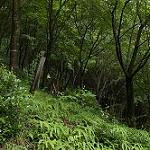
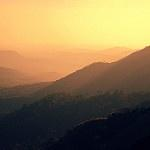
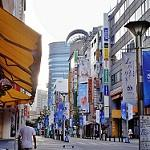
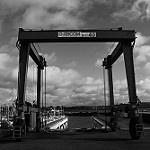
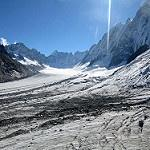
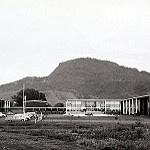
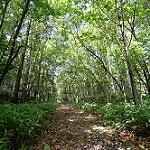
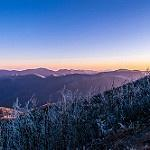
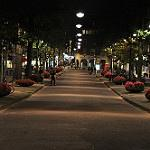
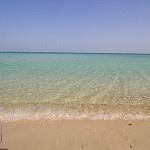
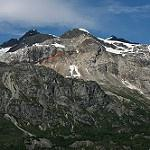
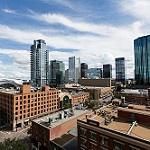
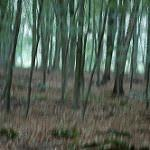
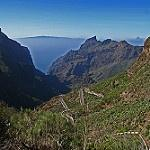
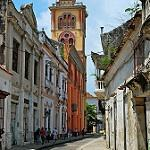
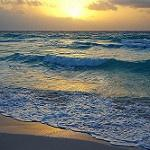
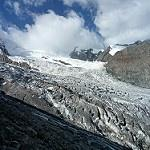
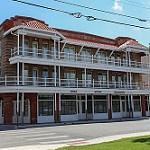
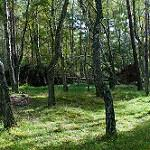
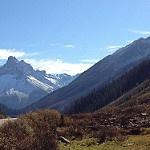
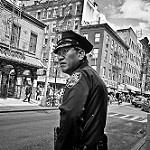
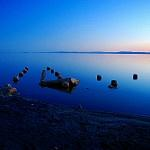
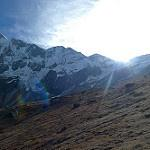
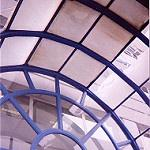
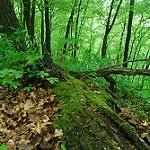
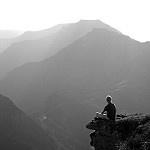
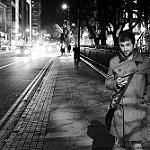
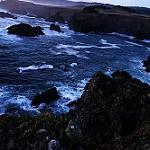
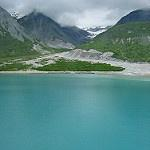
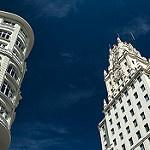

In [ ]:
import os, zipfile, requests, pandas as pd, base64
from PIL import Image
from io import BytesIO
from IPython.display import display, HTML

URL_ZIP = ("https://media.githubusercontent.com/media/witman92/"
           "unsupervised-ml-use-case-discovery/refs/heads/main/"
           "4.-%20Dataset-Clasificaci%C3%B3n%20de%20im%C3%A1genes%20de%20Intel?download=true")
ZIP_PATH, EXTRACT_DIR = "repositorio.zip", "dataset"
BASE_PATH = os.path.join(EXTRACT_DIR, "seg_train", "seg_train")

def obtener_info_imagen(ruta):
    try:
        with Image.open(ruta) as img:                              # Abre la imagen
            buffer = BytesIO()
            img.save(buffer, format="JPEG")                        # Guarda imagen en buffer JPEG
            img_b64 = base64.b64encode(buffer.getvalue()).decode()# Codifica imagen en base64
            return img.size + (f"data:image/jpeg;base64,{img_b64}",)
    except:
        return None, None, None                                    # Retorna None si error

def descargar_extraer(url, zip_path, dest_dir):
    try:
        with requests.get(url, stream=True) as r:
            r.raise_for_status()
            with open(zip_path, 'wb') as f:
                for chunk in r.iter_content(8192): f.write(chunk)  # Descarga en chunks
        with zipfile.ZipFile(zip_path) as z:
            z.extractall(dest_dir)                                # Extrae archivo ZIP
        print("✅ Descarga y extracción completadas.")
        return True
    except Exception as e:
        print(f"❌ Error: {e}")
        return False

def crear_dataframe(base_path, max_imgs=5):
    if not os.path.exists(base_path):
        print(f"⚠️ Ruta no existe: {base_path}")
        return pd.DataFrame()
    datos = {
        cat: [obtener_info_imagen(os.path.join(base_path, cat, f))           # Obtiene info imágenes
              for f in sorted(os.listdir(os.path.join(base_path, cat)))
              if f.lower().endswith(('.jpg','.jpeg','.png'))][:max_imgs]
        for cat in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, cat))
    }
    if not datos:
        print("⚠️ No se encontraron imágenes.")
    else:
        print("✅ DataFrame generado.")
    return pd.DataFrame({k: pd.Series(v) for k, v in datos.items()})      # Crea DataFrame

def mostrar_imagenes(df):
    if df.empty:
        print("No hay imágenes para mostrar.")
        return

    def a_html(info):
        if not info or len(info) != 3 or info[2] is None:
            return ''
        w, h, b64 = info
        return (f'<div style="text-align:center;"><img src="{b64}" width="100">'
                f'<br><span style="font-size:10px;color:#555;">{w}x{h}px</span></div>')  # Formatea HTML

    df_html = df.apply(lambda col: col.apply(a_html))  # Aplica función por columna para evitar warning
    display(HTML(df_html.to_html(escape=False)))       # Muestra tabla HTML con imágenes

def main():
    if descargar_extraer(URL_ZIP, ZIP_PATH, EXTRACT_DIR):
        df = crear_dataframe(BASE_PATH)
        mostrar_imagenes(df)
    else:
        print("🛑 No se pudo completar la descarga y extracción.")

if __name__ == "__main__":
    main()


Resumen técnico del dataset "Clasificación de imágenes de Intel":

Este dataset contiene imágenes aéreas clasificadas en 6 categorías (edificios, bosque, glaciar, montaña, mar y calle), con resolución de 150x150 píxeles. Aunque etiquetado, es útil para tareas de aprendizaje no supervisado en visión por computadora.

Problemas abordables incluyen clustering de imágenes para descubrir subcategorías, detección de anomalías visuales (como deforestación o cambios urbanos) y organización no supervisada de grandes volúmenes de imágenes satelitales.

Se pueden aplicar técnicas como:

Clustering (K-Means, DBSCAN) para agrupar imágenes visualmente similares.

Reducción de dimensionalidad (PCA, t-SNE, Autoencoders) para visualización y preprocesamiento.

Autoencoders Variacionales (VAE) para representaciones latentes y detección de anomalías.

Mapas Autoorganizados (SOM) para exploración topológica de datos de imagen.

# 🧠 Parte 2: Propuesta de proyecto
A partir de los datasets explorados responde para cada dataset (1 dataset de texto, 1 dataset de datos tabulares y 1 dataset de datos de imagenes):

¿Qué problema concreto resolverás? ¿Por qué es relevante?


¿Qué tipo de modelo de aprendizaje no supervisado usaras usarías inicialmente, escoger al menos 2 vistos en clase y 2 no vistos en clase? Explicar teoricamente como funciona el modelo y los algoritmos usados por cada método.

¿Qué métrica de evaluación utilizarás y por qué?

¿Quiénes serían los usuarios o beneficiarios del modelo?

¿Qué esperas lograr con tu modelo? (clasificar, predecir, segmentar, etc.)

¿Qué herramientas planeas usar? (PyTorch, TensorFlow, Keras, etc.)

# DESARROLLO

# Para la :Eleccion 1 "TIPO TEXTO" 8.-Dataset-medidas-respuestas y analisis causa auditorias planta de alimentos..XLSX

## Análisis y Clustering de No Conformidades en Auditorías Planta de Alimentos

## ¿Qué problema concreto resolverás? ¿Por qué es relevante?

Identificar y agrupar automáticamente patrones recurrentes en causas raíz y acciones correctivas de no conformidades detectadas en auditorías de la planta de alimentos. Esto permite:

- **Priorizar** causas raíz frecuentes para mejorar.
- **Optimizar** soluciones estandarizadas.
- **Prevenir** problemas anticipando patrones.
- **Mejorar comunicación** interdepartamental con información estructurada.

## ¿Qué tipo de modelo de aprendizaje no supervisado usarías inicialmente, escoger al menos 2 vistos en clase y 2 no vistos en clase? Explicar teóricamente cómo funciona el modelo y los algoritmos usados por cada método.

### Vistos en clase

1. **K-Means Clustering**  
   - Agrupa datos en k clústeres minimizando la suma de distancias cuadradas a los centroides.  
   - Algoritmo iterativo: asigna puntos al centroide más cercano y recalcula centroides hasta convergencia.  
   - Aplicación: sobre vectores de texto (ej. TF-IDF) para agrupar causas y acciones similares.

2. **PCA (Análisis de Componentes Principales)**  
   - Reduce dimensionalidad buscando combinaciones lineales que capturan mayor varianza.  
   - Se usa para visualización y reducción del espacio vectorial antes del clustering.  
   - Proceso: estandarizar datos, calcular matriz de covarianza, autovalores/vectores, proyectar datos.

### No vistos en clase

3. **Clustering Jerárquico**  
   - Construye una jerarquía de clústeres mediante fusión iterativa (agglomerativo) o división (divisivo).  
   - Visualización en dendrograma para explorar granularidad de agrupaciones.  
   - Útil para entender estructura de problemas y soluciones.

4. **DBSCAN**  
   - Agrupa puntos en regiones de alta densidad, detectando también puntos ruido (outliers).  
   - Parámetros: ε (radio vecindario), minPts (mín. puntos en vecindario para ser clúster).  
   - Ideal para identificar grupos frecuentes y casos atípicos.

## ¿Qué métrica de evaluación utilizarás y por qué?

- **Silhouette Score:** Evalúa cohesión y separación de clústeres, valores cercanos a 1 indican buen clustering.  
- **Davies-Bouldin Index:** Mide similitud entre clústeres; valores bajos indican clústeres bien separados y compactos.  
- **Inspección cualitativa:** Revisión manual para validar sentido y utilidad de agrupaciones en contexto de negocio.

## ¿Quiénes serían los usuarios o beneficiarios del modelo?

- **Equipo de Calidad y Auditoría:** para detectar tendencias y evaluar acciones correctivas.  
- **Gerencia de Planta:** para toma de decisiones estratégicas.  
- **Producción y Mantenimiento:** para enfocar esfuerzos en causas comunes.  
- **Personal operativo:** indirectamente, mejorando procesos y reduciendo problemas.

## ¿Qué esperas lograr con tu modelo? (clasificar, predecir, segmentar, etc.)

- **Segmentar (clusterizar)** no conformidades y acciones correctivas basadas en texto, identificando temas recurrentes, relaciones ocultas y posibles duplicados.  
- Potencial base para futuros modelos supervisados (clasificación o predicción).

## ¿Qué herramientas planeas usar? (PyTorch, TensorFlow, Keras, etc.)

- **Python** (principal lenguaje)  
- **Pandas, NumPy** (manejo y procesamiento de datos)  
- **Scikit-learn** (clustering: K-Means, jerárquico, DBSCAN; PCA; vectorización TF-IDF)  
- **NLTK/SpaCy** (preprocesamiento de texto: tokenización, lematización, stopwords)  
- **Matplotlib/Seaborn** (visualización)  
- **Gensim / Hugging Face Transformers** (opcional: embeddings avanzados como Word2Vec o BERT)  
- **Google Colab** (entorno de desarrollo colaborativo con recursos computacionales)


# Para la :Eleccion 2 " TIPO TABULARES"  9.-Dataset Conjunto de datos de series temporales de viento (por hora).csv

## Análisis de Patrones de Viento y Detección de Anomalías en Series Temporales

## ¿Qué problema concreto resolverás? ¿Por qué es relevante?

Identificar patrones recurrentes y anomalías en las series temporales de velocidad del viento y potencia eólica. Esto es relevante para:

- **Optimizar la operación** de parques eólicos al comprender mejor los patrones típicos del viento.
- **Detectar fallos** en los sensores o eventos meteorológicos extremos mediante la identificación de anomalías.
- **Mejorar la planificación** de la producción de energía al agrupar perfiles de viento similares.

## ¿Qué tipo de modelo de aprendizaje no supervisado usarías inicialmente, escoger al menos 2 vistos en clase y 2 no vistos en clase? Explicar teóricamente cómo funciona el modelo y los algoritmos usados por cada método.

### Vistos en clase

1.  **K-Means Clustering**:
    *   **Teoría:** Agrupa puntos de datos en 'k' clústeres, donde cada punto pertenece al clúster con el centroide más cercano. El algoritmo busca minimizar la suma de las distancias cuadradas entre los puntos y el centroide de su clúster.
    *   **Algoritmo:** Inicia con 'k' centroides aleatorios. Itera asignando cada punto al centroide más cercano y luego actualiza los centroides como la media de los puntos asignados a ese clúster. Repite hasta que los centroides no cambien significativamente.
    *   **Aplicación:** Sobre features extraídas de las series temporales (ej. media, desviación estándar, autocorrelación) para agrupar periodos de tiempo con perfiles de viento similares.

2.  **PCA (Análisis de Componentes Principales)**:
    *   **Teoría:** Técnica de reducción de dimensionalidad que transforma los datos a un nuevo sistema de coordenadas donde las dimensiones (componentes principales) están ordenadas por la cantidad de varianza que explican.
    *   **Algoritmo:** Calcula la matriz de covarianza de los datos, luego encuentra los autovalores y autovectores de esta matriz. Los autovectores corresponden a las direcciones de mayor varianza, y los autovalores indican la magnitud de esa varianza. Se seleccionan los autovectores con los mayores autovalores para formar la base del nuevo espacio.
    *   **Aplicación:** Para reducir la dimensionalidad de las features de las series temporales antes de aplicar clustering, o para visualizar los patrones principales en 2D o 3D.

### No vistos en clase

3.  **Clustering Espectral**:
    *   **Teoría:** Utiliza los autovectores de una matriz de similitud (Laplaciana) de los datos para reducir la dimensionalidad y luego aplica K-Means en el espacio de menor dimensión. Es efectivo para encontrar clústeres no convexos.
    *   **Algoritmo:** Construye un grafo de similitud de los datos, calcula la matriz Laplaciana normalizada, encuentra los 'k' autovectores más pequeños de la Laplaciana, y usa estos autovectores como nuevas características para aplicar K-Means.
    *   **Aplicación:** Para agrupar patrones complejos o no lineales en las series de viento que K-Means tradicional podría no capturar.

4.  **Autoencoders Variacionales (VAE)**:
    *   **Teoría:** Un tipo de red neuronal que aprende una representación latente (codificación) de los datos de entrada. A diferencia de los autoencoders estándar, VAEs aprenden una distribución probabilística en el espacio latente, lo que permite generar nuevas muestras similares a los datos de entrenamiento. La reconstrucción de datos con baja probabilidad en el espacio original puede indicar anomalías.
    *   **Algoritmo:** Consta de un codificador que mapea los datos de entrada a parámetros de una distribución (generalmente Gaussiana) en el espacio latente, y un decodificador que reconstruye los datos a partir de muestras de esa distribución. Se entrena minimizando una función de pérdida que combina el error de reconstrucción y una divergencia KL para regularizar el espacio latente.
    *   **Aplicación:** Para aprender representaciones compactas de los patrones normales de viento y detectar anomalías basándose en el error de reconstrucción o la posición en el espacio latente.

## ¿Qué métrica de evaluación utilizarás y por qué?

-   **Silhouette Score:** Para evaluar la calidad del clustering, midiendo cuán similar es un objeto a su propio clúster en comparación con otros clústeres. Un score alto indica clústeres bien definidos.
-   **Índice de Davies-Bouldin:** Mide el promedio de la "similitud" entre cada clúster y su clúster más similar. Un valor bajo indica que los clústeres están bien separados.
-   **Inspección visual:** Gráficos de las series temporales agrupadas y visualizaciones del espacio latente (PCA, t-SNE, VAE) para interpretar los resultados en el contexto físico.
-   **Métricas de detección de anomalías (si aplica):** Precision, Recall, F1-score si se tiene un conjunto de datos de prueba con anomalías etiquetadas (aunque es un problema no supervisado, se podría simular o usar conocimiento experto para validar).

## ¿Quiénes serían los usuarios o beneficiarios del modelo?

-   **Operadores de parques eólicos:** Para monitorear el rendimiento y detectar problemas.
-   **Ingenieros meteorólogos:** Para analizar patrones climáticos y validar datos.
-   **Empresas de energía:** Para optimizar la generación y el mantenimiento predictivo.
-   **Investigadores:** Para estudiar el comportamiento del viento y desarrollar modelos más avanzados.

## ¿Qué esperas lograr con tu modelo? (clasificar, predecir, segmentar, etc.)

-   **Segmentar (clusterizar)** las series temporales de viento para identificar diferentes regímenes o perfiles de viento (ej. días con viento fuerte y constante, días con viento variable, etc.).
-   **Detectar anomalías** en los datos de viento que podrían indicar fallos en el equipo o eventos meteorológicos inusuales.

## ¿Qué herramientas planeas usar? (PyTorch, TensorFlow, Keras, etc.)

-   **Python** (lenguaje de programación principal).
-   **Pandas, NumPy** (manipulación y análisis numérico de datos).
-   **Scikit-learn** (implementaciones de K-Means, PCA, Clustering Jerárquico, DBSCAN, métricas de evaluación).
-   **TensorFlow / Keras o PyTorch** (para implementar Autoencoders Variacionales).
-   **Matplotlib, Seaborn, Plotly** (visualización de series temporales y resultados de clustering).
-   **Google Colab** (entorno de desarrollo con acceso a GPUs para modelos neuronales).

# Para la :Eleccion 3 "IMAGEN" 10.- Dataset-Clasificación de imágenes de Intel 150x150 en 6 categorías.edificios 0,bosque 1, glaciar 2, montaña 3, mar 4, calle 5

## Análisis y Organización No Supervisada de Imágenes Geográficas

## ¿Qué problema concreto resolverás? ¿Por qué es relevante?

Identificar y agrupar automáticamente imágenes geográficas visualmente similares dentro del dataset Intel 150x150. Esto es relevante para:

-   **Organización eficiente:** Agrupar grandes colecciones de imágenes sin etiquetas predefinidas.
-   **Descubrimiento de patrones:** Identificar subcategorías visuales dentro de las clases existentes o descubrir nuevas agrupaciones.
-   **Detección de anomalías:** Encontrar imágenes que no encajan en ningún grupo principal, lo que podría indicar errores de datos o fenómenos inusuales (ej. cambios en el paisaje).

## ¿Qué tipo de modelo de aprendizaje no supervisado usarías inicialmente, escoger al menos 2 vistos en clase y 2 no vistos en clase? Explicar teóricamente cómo funciona el modelo y los algoritmos usados por cada método.

### Vistos en clase

1.  **K-Means Clustering**:
    *   **Teoría:** Agrupa datos en 'k' clústeres basándose en la similitud de sus características. Las imágenes se representarían como vectores de características (ej. píxeles aplanados, o features extraídas de una red neuronal).
    *   **Algoritmo:** Inicializa 'k' centroides aleatoriamente. Asigna cada imagen al clúster cuyo centroide está más cerca. Actualiza los centroides calculando la media de las imágenes asignadas a cada clúster. Repite hasta que los centroides converjan.
    *   **Aplicación:** Para agrupar imágenes visualmente similares dentro de las 6 categorías o para encontrar subgrupos dentro de ellas.

2.  **PCA (Análisis de Componentes Principales)**:
    *   **Teoría:** Reduce la dimensionalidad de los datos (vectores de imágenes) proyectándolos a un subespacio de menor dimensión que maximiza la varianza.
    *   **Algoritmo:** Calcula la matriz de covarianza de los datos. Encuentra los autovalores y autovectores. Selecciona los 'n' autovectores correspondientes a los mayores autovalores para formar la nueva base y proyecta los datos originales sobre esta base.
    *   **Aplicación:** Para reducir la complejidad computacional antes de aplicar clustering, o para visualizar las imágenes en un espacio 2D o 3D y observar posibles agrupaciones.

### No vistos en clase

3.  **Autoencoders (AE)**:
    *   **Teoría:** Red neuronal con una arquitectura de "cuello de botella" que aprende a comprimir los datos de entrada en una representación latente (codificación) y luego reconstruir los datos originales a partir de esta representación. La capa del "cuello de botella" proporciona una representación de menor dimensión que captura las características esenciales de los datos.
    *   **Algoritmo:** Consiste en un codificador (red neuronal) que mapea la entrada a un espacio latente de menor dimensión y un decodificador (otra red neuronal) que mapea el espacio latente de vuelta al espacio de entrada. Se entrena minimizando el error de reconstrucción (ej. MSE) entre la entrada original y la salida reconstruida.
    *   **Aplicación:** Para aprender representaciones de características eficientes de las imágenes que pueden ser usadas para clustering o visualización.

4.  **Mapas Autoorganizados (SOM - Self-Organizing Maps)**:
    *   **Teoría:** Un tipo de red neuronal artificial que utiliza aprendizaje competitivo para producir una representación discreta (mapa) del espacio de entrada continuo. Proyecta datos de alta dimensión a un espacio de baja dimensión (típicamente 2D) manteniendo las relaciones topológicas de los datos originales.
    *   **Algoritmo:** Inicializa los pesos de los nodos en una cuadrícula 2D. Para cada dato de entrada, encuentra el "mejor nodo ganador" (el nodo con el peso más cercano). Actualiza los pesos del nodo ganador y sus vecinos dentro de un radio decreciente, acercándolos al dato de entrada. Repite para todos los datos de entrada.
    *   **Aplicación:** Para visualizar la estructura latente del dataset de imágenes en un mapa 2D, donde imágenes similares se agrupan en nodos vecinos.

## ¿Qué métrica de evaluación utilizarás y por qué?

-   **Silhouette Score:** Para evaluar la calidad de las agrupaciones generadas por K-Means o Clustering Espectral, indicando qué tan bien separadas están las imágenes dentro de sus clústeres.
-   **Índice de Davies-Bouldin:** Complementa el Silhouette Score midiendo la similitud entre clústeres. Un valor bajo es deseable.
-   **Inspección visual y cualitativa:** Examinar las imágenes dentro de cada clúster para validar si las agrupaciones tienen sentido visual. Para SOM, evaluar la organización visual del mapa.
-   **Métricas de reconstrucción (para Autoencoders):** Error cuadrático medio (MSE) o SSIM para evaluar qué tan bien el Autoencoder reconstruye las imágenes, lo que puede indicar la calidad de la representación latente.

## ¿Quiénes serían los usuarios o beneficiarios del modelo?

-   **Investigadores en teledetección y geografía:** Para analizar patrones espaciales y cambios en el paisaje.
-   **Urbanistas y planificadores:** Para identificar áreas con características similares (ej. tipos de edificios, cobertura vegetal).
-   **Desarrolladores de sistemas de información geográfica (SIG):** Para organizar y buscar imágenes satelitales o aéreas.
-   **Artistas y diseñadores:** Para encontrar imágenes con texturas o composiciones visuales específicas.

## ¿Qué esperas lograr con tu modelo? (clasificar, predecir, segmentar, etc.)

-   **Segmentar (clusterizar)** las imágenes para descubrir grupos visualmente homogéneos, incluso si no corresponden directamente a las etiquetas originales o si existen subgrupos dentro de ellas.
-   **Obtener representaciones compactas y significativas** de las imágenes (mediante PCA o Autoencoders) para facilitar la visualización, el análisis y potencialmente como preprocesamiento para otras tareas.
-   **Visualizar la estructura del espacio de imágenes** (mediante PCA, t-SNE o SOM) para entender las relaciones entre las diferentes categorías visuales.

## ¿Qué herramientas planeas usar? (PyTorch, TensorFlow, Keras, etc.)

-   **Python** (lenguaje de programación principal).
-   **OpenCV, PIL (Pillow)** (carga y preprocesamiento de imágenes).
-   **NumPy** (manipulación de arrays numéricos).
-   **Scikit-learn** (implementaciones de K-Means, PCA, métricas de evaluación).
-   **TensorFlow / Keras o PyTorch** (para implementar Autoencoders y posiblemente SOM si se usa una librería basada en redes neuronales).
-   **TensorFlow-SOM o alguna otra librería específica para SOM** si no se implementa manualmente.
-   **Matplotlib, Seaborn, Plotly** (visualización de resultados y el mapa SOM).
-   **Google Colab** (entorno de desarrollo, especialmente si se usan Autoencoders que requieren GPU).